# 03-Ymodem协议原理与接收实现


## 1. 本篇内容与实验目标

本篇接着 Flash 擦写实验，按课程顺序学习 **Ymodem 如何把电脑上的文件可靠地传到 GD32，并写入指定 Flash 地址**。覆盖讲义 `OTA远程升级.pdf` 第 **31—39 页**（PDF 物理页码）和以下七段视频。

| 视频 | 时长 | 主要内容 |
|---|---|---|
| `05_Ymodem协议_核心概念.mp4` | 12:57 | 帧结构、控制字符、文件传输会话 |
| `06_Ymodem实操_GD32接收准备.mp4` | 5:23 | 两路串口、接收入口、App 存储区 |
| `07_Ymodem实操_传输txt文件.mp4` | 8:43 | SecureCRT 发送文本，Memory 检查 Flash |
| `08_Ymodem实操_C语言核心流程.mp4` | 10:28 | 先用 C 语言日志模拟接收主线 |
| `09_Ymodem实操_单文件传输流程.mp4` | 9:37 | 头包解析、擦除、分包写入与 EOT |
| `10_Ymodem实操_CRC16校验.mp4` | 7:15 | Keil 断点与 CRC-16/XMODEM 验证 |
| `11_Ymodem实操_多文件传输.mp4` | 9:39 | 外层文件循环、空头包收尾、多文件覆盖实验 |

资料来自[课程百度网盘](https://pan.baidu.com/s/19vzB65qjPtH6BEy0EBZ5VQ?pwd=1234)，提取码 `1234`。本篇读取了视频 05、06、08—11 的完整 AI 中文字幕，对照讲义原图、视频 07 的实操关键画面及 `Code.zip` 中单文件／多文件接收工程。07 未取得现成字幕，其操作根据画面和配套代码整理。

课堂使用 **GD32F407VET6，512 KB 片上 Flash**。下文的编译、串口、烧录和 Memory 现象均为课程演示；本机没有连接开发板执行硬件实验。本篇完成文件接收与存储，App 启动和跳转留到下一篇。


## 2. 为什么需要 Ymodem 文件传输协议

串口解决“字节怎样传过去”，但直接连续发送文件字节，还没有说明文件名、总长度、分包边界、出错后的重传和传输结束方式。Ymodem 在串口数据上约定这些规则，让发送工具与接收程序可以配合工作。

| 能力 | 在本课中的作用 |
|---|---|
| 头包携带文件名和长度 | 提前判断容量，安排 Flash 擦除，识别真实文件大小 |
| 128／1024 字节数据区 | 小包适合尾部，大包减少握手和包头开销 |
| CRC16 校验 | 检测数据区在传输中是否发生差错 |
| ACK／NAK 与重传 | 接收成功再确认，失败时请求重发 |
| 一次会话发送多个文件 | 文件结束后继续接收下一文件头，最后统一结束会话 |

Ymodem 从 Xmodem 发展而来。传统 Xmodem 有 8 位累加校验版本，也有 Xmodem-CRC 变体；不能把它们一概称为“CRC8”。课程选择 Ymodem，主要看中 CRC16、大数据包和文件元信息，并使用 SecureCRT 验证。

**概念校正：**CRC 是检错机制，恢复靠协议重传；标准 Ymodem 本身不承诺断电后断点续传。本课程序每个文件都会从 App 起始区擦写，没有持久化传输偏移，也没有实现掉电续传。


## 3. 一帧数据由哪些字节组成

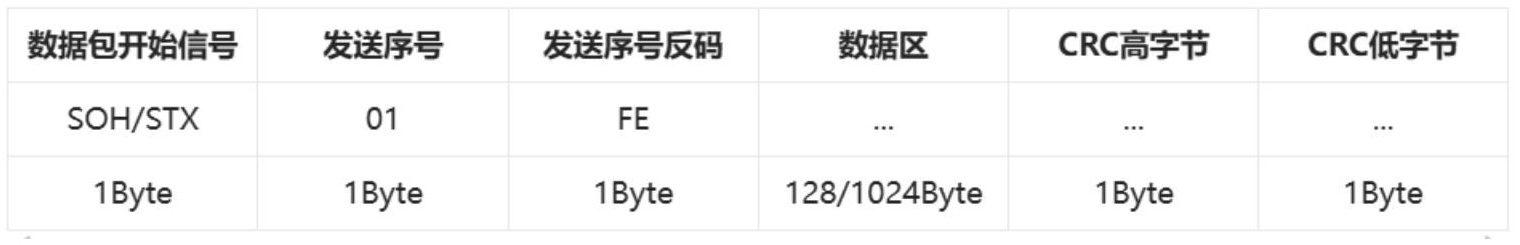

*讲义第 35 页，裁取帧结构表。*

```text
SOH / STX | 包序号 | 包序号反码 | 数据区（128 或 1024） | CRC高字节 | CRC低字节
   1      |   1    |     1      |        N            |     1     |     1
```

| 字段 | 取值／长度 | 说明 |
|---|---|---|
| `SOH` | `0x01` | 数据区为 128 字节，整帧 `128 + 5 = 133` 字节 |
| `STX` | `0x02` | 数据区为 1024 字节，整帧 `1024 + 5 = 1029` 字节 |
| 序号 | 1 字节 | 文件头包为 `00`，数据包从 `01` 开始，`FF` 后按 8 位回绕 |
| 序号反码 | 1 字节 | 例如 `01` 对应 `FE`，`02` 对应 `FD` |
| 数据区 | 128 或 1024 字节 | 头包放元信息，后续包放文件内容，最后一包可有填充 |
| CRC | 2 字节 | 只计算数据区，先发送高字节，再发送低字节 |

**序号校验补充：**讲义和配套代码使用 `seq | inverse == 0xFF`。这个条件不够严格，例如 `FF | FF` 也等于 `FF`。真正的反码关系应检查 `(uint8_t)(seq ^ inverse) == 0xFF`，或 `inverse == (uint8_t)~seq`；这还不能代替“是否为当前期待包号”的检查。

`EOT = 0x04` 是单独的结束控制字节，不是带数据区和 CRC 的普通帧。


## 4. 第 0 号头包怎样表示文件名和长度

头包仍使用相同帧结构，但序号为 `00`、反码为 `FF`，数据区表示文件元信息。课程示意：

```text
SOH 00 FF | foo.c 00 4196 20 ...补齐数据区... | CRC_H CRC_L
             文件名  \0  大小ASCII  空格
```

这里的 `4196` 是字符 `'4' '1' '9' '6'`，不是一个直接占 4 字节的小端整数。文件名后的 `00` 表示 C 字符串结束；大小后可以有空格和时间戳等可选信息。

接收端拿到头包后，要先检查长度是否能放入 App 区，再准备擦除，随后回复 `ACK` 和字符 `C`。头包的名字、大小等信息用于管理传输，**不作为文件内容写进 App 区**。

会话结束时，发送端还会发一个序号 `00` 的头包。这个包的文件名首字节为 `00`，表示“没有下一文件”。它与“名字非空但文件大小为 0”的空文件不是一回事。


## 5. 从字符 C 到空头包：完整会话时序

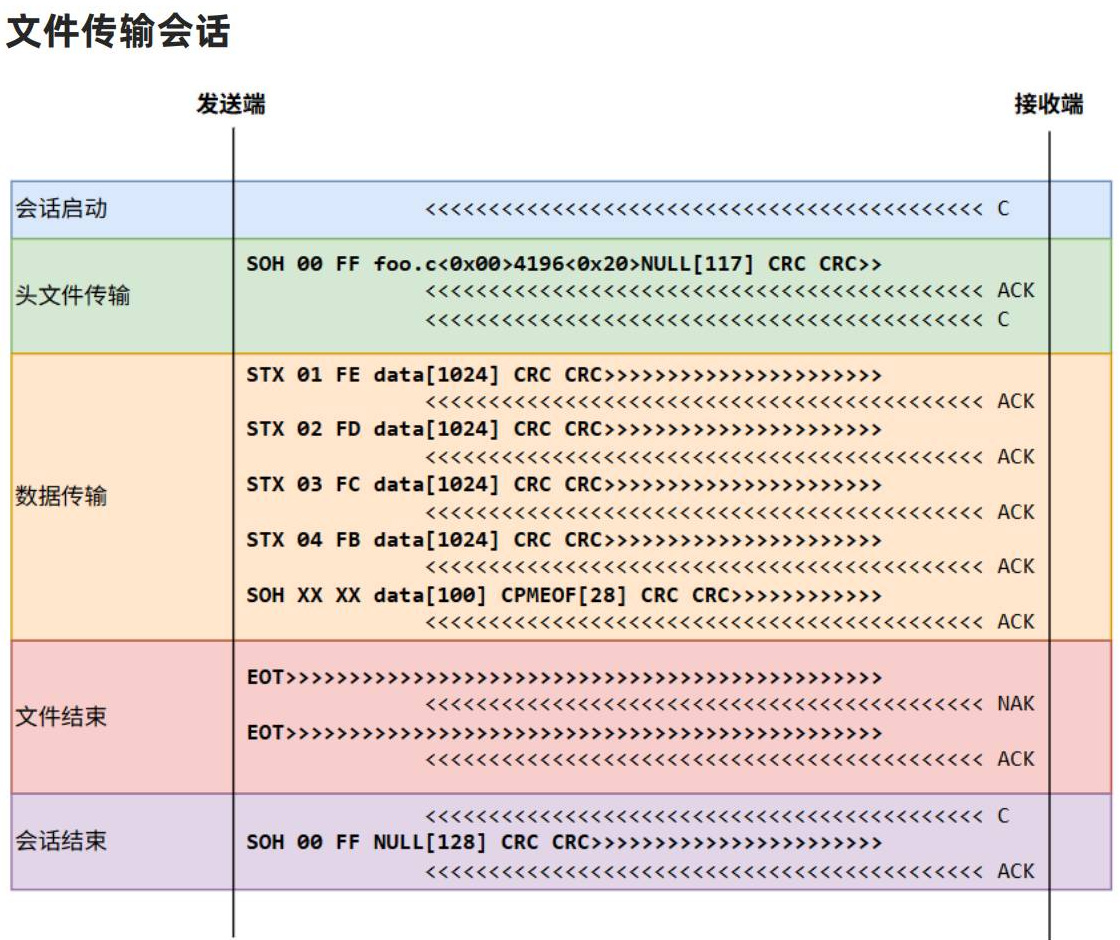

*讲义第 36 页：左边为发送端，右边为接收端。绿色是头包，橙色是数据，红色是文件结束，紫色是会话收尾。*

| 阶段 | 发送端（电脑） | 接收端（GD32） |
|---|---|---|
| 请求开始 | 等待请求 | 周期性发送 `C = 0x43`，请求 CRC 模式传输 |
| 文件头 | 发送序号 `00` 的文件名／大小头包 | 校验、解析、检查空间、准备 Flash，回复 `ACK = 0x06`，再发 `C` |
| 文件数据 | 从序号 `01` 开始发送数据帧 | 每包校验通过并处理后回复 `ACK` |
| 第一次结束 | 发送第一个 `EOT = 0x04` | 回复 `NAK = 0x15` |
| 第二次结束 | 再发一次 `EOT` | 回复 `ACK`，该文件完成 |
| 下一个文件 | 收到新的 `C` 后发下一头包 | 发送 `C` 请求下一头包 |
| 整个会话结束 | 若无下一文件，发送空文件名头包 | 回复 `ACK`，退出会话 |

只有一个文件时也要完成最后一行。**文件字节收齐、单个文件 EOT 握手结束、整个会话结束，是三个不同的时刻。**

多文件传输只需重复“头包→数据→两个 EOT”，最后再用空文件名头包收尾。


## 6. CRC 出错时为什么应回复 NAK

讲义第 37 页让我们判断：如果第 3 个数据包 CRC 错了，接收端应该回复什么？答案是 **`NAK`，请求发送端重传当前包**。

正常流程是“收包→检查帧和序号→CRC→处理数据→ACK”。失败包不能当成新数据写入 Flash，也不能推进目标地址。ACK 若丢失，发送端可能重发已经接收过的上一包；接收程序还应识别这种重复包并重新 ACK，避免再次写入和移动地址。

`C` 主要用于发起 CRC 模式传输或请求文件头，`ACK` 表示确认，`NAK` 表示拒绝并请求重传，不能混为同一种响应。

**对照课堂源码：**本课 `YmodemReceive()` 把一般非零接收错误统一处理为 `SendByte(CREQ); continue;`，并没有按状态对 CRC 错误发 NAK，也没有实现期待包号／重复包判断。下文保留这段教学代码，但不能据此说它已经实现完整的标准重传逻辑。


## 7. 文件大小、数据区长度和整帧长度要分清

讲义时序图的文件为 **4196 字节**：前四个 1 KB 包是 `4096` 字节，最后只剩 `100` 个有效字节，可以放在一个 128 字节的 SOH 数据区中，另有 `28` 字节填充。图中的 `CPMEOF` 通常为 `0x1A`。

```text
真实文件长度：4 × 1024 + 100 = 4196
数据区总长度：4 × 1024 + 128 = 4224
最后一帧长度：3 + 128 + 2 = 133
```

接收端仍须收完整个数据区和 CRC，并对包含填充的完整数据区验 CRC。保存文件时，再根据头包声明的总大小，只保留最后包中有效的部分。**不能因为只剩 100 字节，就只从串口读 100 字节；也不能把 28 字节填充算进真实文件。**

本课变量 `packetLength` 指 **128／1024 字节数据区**，既不是整帧长度，也不是当前包的有效文件字节数。课堂源码按 `packetLength` 全量写入，包括最后的填充；用于实际固件时还需按剩余长度裁定写入字节数，并检查写入地址范围。


## 8. GD32 接收工程：两路串口各做什么

先打开配套工程 `03_GD32F407_IAP_Bootloader/Project/GD32F407.uvprojx`。在 `Common` 组加入 `update.c`，配套头文件为 `update.h`，依赖前篇的 Flash 驱动、`tools.c` 和串口驱动。

| 通道 | 用途 | 本工程配置 |
|---|---|---|
| `USART0` | 与 SecureCRT 收发 Ymodem 协议 | 115200，TX=`PA9`，RX=`PA10`，AF7 |
| `USART1` | 输出接收过程和包长度等调试日志 | 115200，TX=`PD5`，RX=`PD6`，AF7 |

`Library/USART/USART_config.h` 中启用 `USE_USART0=1`、`USE_USART1=1`。USART0 使用轮询接收：`USART0_RX_INT=0`，收发 DMA 均为 `0`。`USART0_PRINTF=1`，`USART1_PRINTF=0`，所以 `printf()` 仍走 **USART0**；过程日志明确调用 `USART1_send_string()`。

这意味着 `printf()` 可在传输开始前、会话结束后输出提示，**传输过程中不要向 USART0 混入普通调试文本**，否则会干扰二进制协议。

*接线补充：*使用 USB 转串口时，转换器 TX 接 MCU RX，转换器 RX 接 MCU TX，并共地；两路电脑串口分别对应协议和日志，COM 编号以本机设备管理器为准。不要照抄教师机器上的 COM 号。


## 9. 接收入口与 App 存储空间

`User/main.c` 包含 `update.h`，完成滴答定时器、延时、串口和 GPIO 初始化后，先打印启动消息，再调用阻塞式的 `UpdateApp()`：

```c
printf("Bootloader------------------\r\n");
USART1_send_string("Bootloader USART1\r\n");

// 阻塞式等待接收Ymodem协议数据
UpdateApp();

while (1) {
    gpio_bit_toggle(GPIOB, GPIO_PIN_2);
    DelayNms(500);
}
```

因此接收未返回时，不会执行后面的 LED 翻转循环。`Common/update.h` 定义当前实验的目标区：

```c
#define FLASH_SIZE          0x80000
#define APP_ADDR_IN_FLASH   0x08004000
#define FLASH_APP_SIZE      (FLASH_SIZE - (APP_ADDR_IN_FLASH - FLASH_BASE))
```

Flash 基址 `0x08000000`，总大小 512 KB；App 从 `0x08004000` 开始，前面预留 16 KB，App 可用空间为 **`0x7C000 = 496 KB = 507904` 字节**，结束地址为 `0x0807FFFF`。这是本阶段实验分区，后续按课程设计再调整。

`UpdateApp()` 用 `int32_t imageSize` 保存返回值：正数表示文件大小，负数表示错误。不能改成无符号数，否则无法正确比较 `-1` 等错误码。函数返回文件大小也不等于已经完成 App 跳转。


## 10. SecureCRT 发送前的配置

视频 07 先介绍 SecureCRT 的中文显示设置，再建立 Serial 会话，与 GD32 的 USART0 连接。复现实验时检查以下项目：

1. 根据设备管理器选实际串口；速率设为 **115200**，8 位数据位、无校验、1 位停止位，与固件串口初始化保持一致。
2. 两端没有连接硬件流控线时，关闭相应硬件流控。另一路串口工具连接 USART1，用来观察过程日志。
3. 中文提示乱码时，在 `Options → Global Options → Default Session → Edit Default Settings → Terminal → Appearance` 中核对字符编码。课件示范使用 **GB2312**，并演示将默认设置应用到会话。编码只影响终端文字显示，不改变 Ymodem 二进制文件内容。
4. GD32 运行到接收循环后，USART0 会出现连续的字符 `C`。这是接收端请求 CRC 模式传输，不是文件内容或程序报错。
5. 选择 `Transfer → Send Ymodem`，在文件选择窗口中添加要传输的文件，再开始发送。不要使用普通“发送文本”来替代协议发送。

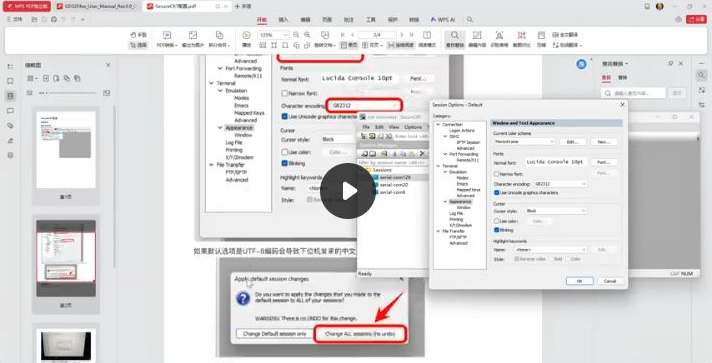

*视频 07 约 00:57 的课堂画面：左侧课件标出字符编码和默认会话应用选项，右侧为实际设置窗口。*

如果同一个电脑串口已被其他串口助手占用，先释放该通道，再交给 SecureCRT；USART1 的日志通道可以独立打开。


## 11. 先传 abc123.txt，再用 Memory 验证

视频 06 准备一个便于识别的重复文本，视频 07 用它验证传输。配套工程中的 `abc123.txt` 实际为 **6390 字节**，开头反复出现 `abcde12345`。文本只是实验载荷，能观察字节是否正确写入，不要求它是可执行固件。

课堂操作按以下顺序进行：

1. 编译并下载接收工程，进入 Keil Debug，在接收返回后的结果处理位置设置断点；Memory 关注 `0x08004000`。
2. 让程序继续运行，确认已进入等待传输，SecureCRT 终端收到重复的 `C`。
3. 打开 `Transfer → Send Ymodem`，添加 `abc123.txt`，开始传输；另一路串口查看文件名、`size->6390`、包长度及 `fileDone NAK`／`fileDone ACK!!!` 等过程信息。
4. 接收结束后检查 Memory。课堂画面中该地址已出现文本对应的十六进制字节，例如 `61 62 63 64 65 31 32 33 34 35` 对应 `abcde12345`。切换 ASCII 显示更容易与原文件对照。

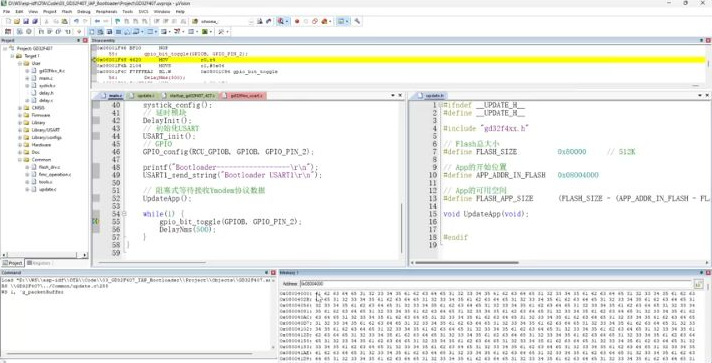

*视频 07 约 07:13，Memory 地址为 App 区，已经出现接收到的文本字节。*

这一阶段的单文件版本在第二个 EOT 后就退出，尚未完成整个 Ymodem 会话。画面中的 SecureCRT 仍可能处于传输状态，最终普通日志没有正常显示。应结合 USART1 和 Memory 判断“是否收到了数据”，再在视频 11 完善会话收尾；不能仅凭终端没有成功文字，就判定 Flash 没有写入。


## 12. C 语言模拟：先看懂接收主线

视频 08 先在纯 C 环境中通过日志和注释模拟 `YmodemReceive()`，用来分清“文件头”和“数据包”，此时的模拟不是真正操作串口和 Flash。

```text
初始化：已收包数 = 0，目标地址 = 0x08004000
循环接收一个包
  第一个包：解析文件名和大小 → 准备Flash → ACK → C
  后续包：取数据区 → 写入目标地址 → 目标地址加本包长度 → ACK
  已收包数加1
```

模拟中的文件示意为 `OTA_v1.2.bin`、4904 字节。课程用固定的 128 字节步长展示地址变化，直至到达文件范围；实际程序须使用本包的 `packetLength`，因为 SOH 和 STX 的数据区大小不同。

**这里的模拟只用于理解数据流。**“累计长度达到文件大小”可以判断有效内容已到齐，但完整接收器还要处理 EOT 和会话末尾空头包。本篇后面回到提供的 Keil 工程，按真实收包、校验、擦写流程分析。当前 `Code.zip` 未包含视频中该独立 C 模拟文件，下面代码摘录均来自实际 GD32 工程。


## 13. 真实代码的分层与状态变量

回到视频 09 的 Keil 工程。主要调用关系如下，名字按配套源码保留：

```text
main()
 └─ UpdateApp()                   提示、调用接收、最后打印结果
     └─ YmodemReceive()            管理文件传输，擦除并写入Flash
         ├─ RecevicePacket()      接收一帧，检查反码和CRC
         │   ├─ USART0_RecviveByteTimeout()
         │   └─ Crc16Ymodem()
         ├─ getFileInfo()          解析文件名、声明大小
         ├─ FlashErase()
         └─ FlashWrite()
```

`RecevicePacket` 和 `USART0_RecviveByteTimeout` 的拼写就是源码中的名称，查找时不要自行改成另一种拼法。`Common/update.c` 的重要变量是：

| 变量／常量 | 含义 |
|---|---|
| `packetData[1024 + 5]` | 一整帧接收缓冲，包括头、数据区和 CRC |
| `packetLength` | 已通过校验的数据区长度，SOH=128，STX=1024；EOT 时为 0 |
| `packetsReceived` | 当前文件已处理包数，用 0 区分第一包；不是协议期待序号 |
| `fileSize` | 从头包字符串解析出的真实文件总大小 |
| `fileDone` | 单个文件的 EOT 阶段，第一 EOT 后置 1 |
| `flashDestinaiton` | 下一次写入 Flash 的目标地址，源码保留此拼写 |
| `g_packetBuffer[1024]` | 静态数据区暂存缓冲，不含帧头和 CRC |
| `g_imageName[256]` | 当前文件名，供日志与最终结果显示 |
| `PACKET_HEADER`／`PACKET_OVERHEAD` | 分别为 3 和 5 字节 |

包数量、包序号和已写入文件字节数不能混用。本课用包数量识别头包，但完整实现还需单独维护期待包号与有效字节数。


## 14. RecevicePacket：先读帧头，再按长度接收

下面摘录配套 `Common/update.c` 的完整单包接收函数。它先将输出长度清零，再根据 SOH／STX 决定要读多少字节。收到 EOT 时直接返回成功且长度保持 0，交给上层处理结束握手。

```c
int RecevicePacket(uint8_t* data, int32_t* length, uint32_t timeout){

    uint32_t packageSize = 0; // 数据包大小
    *length = 0; // 一定要把长度清零
    
    uint8_t c;
    
    // 获取消息头
    if(!USART0_RecviveByteTimeout(&c, timeout)){
        return -10; // 超时
    }
    
    // 判断消息头
    switch(c){
        case SOH:  // 128字节数据包开始
            packageSize = 128;
            break;
        case STX:  // 1024字节数据包开始
            packageSize = 1024;
            break;
        case EOT:  // 结束传输
            packageSize = 0;
            return 0;
        case CA:  // 0x18, 这两个相继中止转移, 连续收到两个0x18,说明用户按下了Ctrl + C
            if(USART0_RecviveByteTimeout(&c, timeout) && c == CA){
                return -11; // 用户主动中断发送
            }else{
                return -12; // 用户主动中断发送
            }
        case ABORT1:  // 'A' == 0x41, 用户终止
        case ABORT2:  // 'a' == 0x61, 用户终止
            return -13; // 用户主动终止
        default:  // 其他情况
            return -14; // 其他情况
    }

    // 将帧头存到数据包中
    data[0] = c;
    // 循环接收N-1个数据
    uint32_t packageTotal = packageSize + PACKET_OVERHEAD;
    for(int i = 1; i < packageTotal; i++){
        if(!USART0_RecviveByteTimeout(&data[i], timeout)){
            return -15; // 超时
        }
    }

    // 接收数据包完成, 校验序列号和反序列号
    if((data[PACKET_SEQNO_INDEX] | data[PACKET_SEQNO_COMP_INDEX]) != 0xFF){
        return -16; // 序列号或反序列号错误
    }

    // 计算实际的CRC16
    uint16_t expect_crc = (data[packageTotal - 2] << 8) | data[packageTotal - 1];
    uint16_t actual_crc = Crc16Ymodem(&data[3], packageSize);
    if(expect_crc != actual_crc){
        return -17; // CRC16校验失败
    }

    // 数据包校验通过
    *length = packageSize;

    return 0;
}
```

`packageTotal = packageSize + 5` 是整帧长度。第一个字节已经放进 `data[0]`，所以循环从 1 开始接收其余字节。CRC 从最后两字节取出，计算范围是 `&data[3]` 开始的 `packageSize` 个字节。

注意本函数的成功条件是 **返回值为 0**。只有成功后，`length` 才能用来区分有效数据包和 EOT；不能把“接收错误时同样为 0 的 length”误当 EOT。

`Library/USART/USART0.c` 中的超时函数实质是 `while (timeout--)` 反复轮询。`NAK_TIMEOUT = 0x100000` 是循环次数预算，**不是毫秒值**，实际等待时间与时钟、编译优化和循环实现有关。这里还有前文指出的 OR 反码检查不严格的问题。


## 15. getFileInfo：从头包提取名字与总大小

头包校验成功后，`getFileInfo()` 从 `packetData + PACKET_HEADER` 开始读取文件名，跳过文件名末尾的 `\0`，再读取 ASCII 文件大小，最后调用 `Str2Int()`。

```c
void getFileInfo(uint8_t *packetData, int32_t *size) {
  int32_t i;
  uint8_t fileSize[FILE_SIZE_LENGTH];

  uint8_t *filePtr;
  /* 跳过3个字节，取出文件名，直到遇到0x00(\0), Filename packet has valid data
   */
  for (i = 0, filePtr = packetData + PACKET_HEADER; (*filePtr != '\0') && (i < FILE_NAME_LENGTH); ) {
    g_imageName[i++] = *filePtr++;
  }
  g_imageName[i++] = '\0';

  /* 取出数据总长度，直到遇到空字符 */
  for (i = 0, filePtr++; (*filePtr != ' ') && (i < FILE_SIZE_LENGTH);) {
    fileSize[i++] = *filePtr++;
  }
  fileSize[i++] = '\0';
  // 将数字字符串转成int32_t类型数字
  Str2Int(fileSize, size);
}
```

例如讲义 CRC 样本中数据区开头为：

```text
OTA_v1.2.bin<NUL>4904 14732475107 0 ...
```

其中 `<NUL>` 代表一个 `0x00` 字节，紧接着就是大小字符 `4904`。`getFileInfo()` 只取名字和大小，后面的可选字段不参与 App 文件内容写入。

解析后先判断 `fileSize > FLASH_APP_SIZE`。若超容量，就发送两个 `CA = 0x18` 取消并返回 `-1`；容量允许才调用 `FlashErase()`，再发 `ACK` 和 `C`，表示可以发文件数据。

*源码边界补充：*该教学解析器对包内边界、数组末尾 NUL 空间和 `Str2Int()` 失败的处理不完整。真实工程应在数据区内限定读取范围，校验大小有效且非负，再使用该长度擦写 Flash。


## 16. 单文件接收：头包准备，数据包顺序写入

`YmodemReceive()` 的单文件版本先设置目标地址 `APP_ADDR_IN_FLASH`，随后阻塞收包。以下是头包与数据包分支的关键代码，省略了日志：

```c
if (packetsReceived == 0) {
    getFileInfo(packetData, &fileSize);
    if (fileSize > FLASH_APP_SIZE) {
        SendByte(CA);
        SendByte(CA);
        return -1;
    }
    FlashErase(flashDestinaiton, fileSize);
    SendByte(ACK);
    SendByte(CREQ);
} else {
    memcpy(g_packetBuffer, packetData + PACKET_HEADER, packetLength);
    FlashWrite(flashDestinaiton, g_packetBuffer, packetLength);
    flashDestinaiton += packetLength;
    SendByte(ACK);
}
packetsReceived++;
```

`packetData + PACKET_HEADER` 表示 **跳过前 3 字节**，不是把 3 加到复制长度。这样传给 `FlashWrite()` 的是数据区，协议头和 CRC 都不会写入 App 区。复制后按本包数据区长度推进地址，下一包紧接着存储。

EOT 分支如下，对应时序图的红色部分：

```c
if (packetLength == 0) {
    if (fileDone == 0) {
        fileDone = 1;
        SendByte(NAK);
    } else if (fileDone == 1) {
        SendByte(ACK);
        break;
    }
    continue;
}
```

单文件版本第二个 EOT 后 `break`，最终 `return fileSize`。它还没有等待下一头包，所以即使只传一个文件，也没有完成协议的会话收尾，这正是视频 11 要继续补上的内容。

**擦写补充：**本课没有检查 `FlashErase()`／`FlashWrite()` 的返回值，失败后仍可能回复 ACK。且前篇已经指出 `FlashErase()` 在扇区边界的地址计算问题；准备实际升级器时应先修复并验证这些边界，不能把最后的“烧录成功”日志当作独立的完整回读校验。


## 17. 为什么要增大启动文件中的栈

本地接收数组为 `uint8_t packetData[1024 + 5]`，单它就需要 **1029 字节**。若启动文件默认栈只有 `0x400 = 1024` 字节，连数组本身都放不下，还没有计算其他局部变量、函数调用和中断栈开销。

视频 09 提醒在启动汇编中调整 `Stack_Size`，例如设为 `0x800` 或 `0x1000`。配套 ARM 启动文件路径为：

```text
Firmware/CMSIS/GD/GD32F4xx/Source/ARM/startup_gd32f407_427.s
```

当前代码包中的实际值已为：

```asm
Stack_Size      EQU     0x00001000
Stack_Mem       SPACE   Stack_Size
```

调整后重新编译、下载，再调试。另一种做法是把大数组放到静态／全局存储区，但会占用常驻 RAM，也要考虑重入。本课采用增大栈的办法；4 KB 是此实验的配置，不是任意工程都足够的保证。


## 18. CRC-16/XMODEM 的参数与实现

`Common/tools.c` 中的 `Crc16Ymodem()` 是以下实现：

```c
uint16_t Crc16Ymodem(uint8_t *data, uint16_t length) {
    uint8_t i;
    uint16_t crc = 0;  // Initial value
    while (length--) {
      crc ^= (uint16_t)(*data++) << 8;
      for (i = 0; i < 8; ++i) {
        if (crc & 0x8000)
          crc = (crc << 1) ^ 0x1021;
        else
          crc <<= 1;
      }
    }
    return crc;
  }
```

| 参数 | 本课取值 |
|---|---|
| 位宽 | 16 |
| 多项式 | `0x1021` |
| 初值 | `0x0000` |
| 输入反射／输出反射 | 均为 false |
| 最终异或值 | `0x0000` |
| 发送顺序 | 高字节在前、低字节在后 |

每取一个数据字节，先异或到 CRC 高 8 位，再逐位左移 8 次；若移位前最高位为 1，就异或多项式。CRC 在 `uint16_t` 中保留 16 位结果。

单包接收函数中的对应比较为：

```c
uint16_t expect_crc = (data[packageTotal - 2] << 8)
                    | data[packageTotal - 1];
uint16_t actual_crc = Crc16Ymodem(&data[3], packageSize);
if (expect_crc != actual_crc) {
    return -17;
}
```

要匹配的是算法全部参数和输入范围。只选一个名称带“CRC16”的算法，或者把帧头也加进去，结果都可能不同。CRC 通过说明本包数据区通过这一检错机制；它不验证固件来源，也不负责确认 Flash 写入后的内容。


## 19. Keil 断点与在线 CRC 交叉验证

视频 10 先在 `RecevicePacket()` 的 CRC 比较附近打断点，查看 `expect_crc` 与 `actual_crc`。若在高优化等级下 Watch 无法显示局部变量，课程操作是：

1. 打开 `Options for Target → C/C++ → Optimization`，将 O3 改为 **Level 0（O0）**。
2. 重新编译、下载、进入 Debug，在 CRC 计算完成后暂停。Call Stack 可以看到 `main → UpdateApp → YmodemReceive → RecevicePacket`。
3. 让程序先运行到等待接收，发出字符 `C`，再在 SecureCRT 选择 `Send Ymodem`。若在接收请求发出前一直停在断点，发送工具会等待。
4. 检查 `expect_crc == actual_crc`；再在 Memory 查看本次 `data` 指针地址处的完整帧。课堂示例出现的 `0x2000195F` 是当时 RAM 地址，每次布局可能改变，不能作为固定配置。
5. 用[课堂指定的在线 CRC 工具](https://www.lddgo.net/encrypt/crc)，输入类型选择 Hex，算法选择 **CRC-16/XMODEM**，只填中间完整的 128 字节数据区，再与帧尾两字节比较。

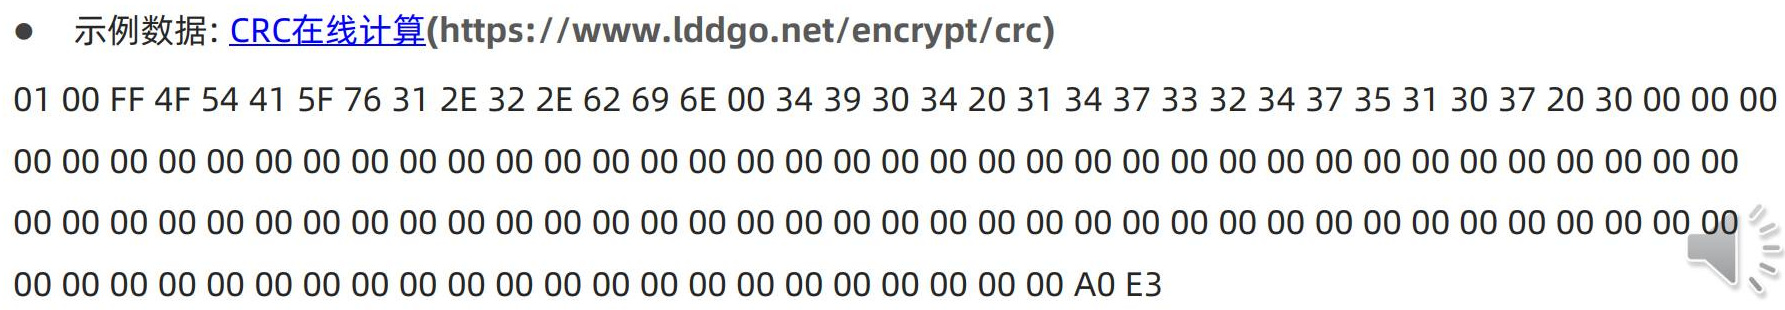

*讲义第 39 页的原始样本。开头 `01 00 FF` 是 3 字节头，末尾 `A0 E3` 是 CRC，二者都不进入计算。*

样本文件名为 `OTA_v1.2.bin`，声明大小为 `4904`。按原图，后面的字段字符串为 `14732475107 0`。原图大小写和每一个空格都影响 CRC，不能改写后再期待相同结果。

可离线复核同一数据区（补充示例，不连接硬件）：

```python
import binascii

payload = b"OTA_v1.2.bin\x00" + b"4904 14732475107 0"
payload = payload.ljust(128, b"\x00")
crc = binascii.crc_hqx(payload, 0)
print(f"{crc:04X}")  # A0E3
```

本篇已用该样本复算，结果是 **`0xA0E3`，对应线上字节 `A0 E3`**。课堂字幕对该数值的识别不稳定，以讲义原始字节和计算结果为准。样本的 4904 字节也不要与代码包当前提供的其他版本固件大小混用。


## 20. 多文件接收：在包循环外再加文件循环

视频 11 打开 `03_GD32F407_IAP_Bootloader2/Project/GD32F407.uvprojx`，其中 `Common/update.c` 已提供多文件版本。

原来的一层循环负责“一个文件的多个包”；外面再套一层，负责“一次会话的多个文件”。每个新文件先重置包计数和 EOT 状态；遇到空文件名头包时，回复 ACK 并结束整个会话。

```c
// 按配套源码整理的结构，省略收包、错误处理与数据写入细节
while (1) {                        // 一次会话的多个文件
    flashDestinaiton = APP_ADDR_IN_FLASH;
    packetsReceived = 0;
    fileDone = 0;

    while (1) {                    // 一个文件的多个包
        // RecevicePacket(...)
        // 第一个EOT: NAK；第二个EOT: ACK，并break内层

        if (packetsReceived == 0) {
            if (packetData[PACKET_HEADER] == 0x00) {
                SendByte(ACK);
                sessonDone = 1;    // 源码变量名
                break;
            }
            // 解析新文件头、检查空间、擦除、ACK + C
        } else {
            // 保存数据区、更新地址、ACK
        }
        packetsReceived++;
    }

    if (sessonDone > 0) {
        break;
    }
}
```

`packetData[PACKET_HEADER]` 就是数据区的第一个字节，即文件名首字节。它为 0，表示发送端没有下一文件；非 0 则开始下一个文件。这里的检测在成功接收并校验头包之后执行。

**与时序图对照：**代码包第二个 EOT 后只明确发 ACK，没有立刻显式发送下一个 `C`。外层循环再次进入收包，超时得到 `-10` 后，经通用错误分支发送 `C`，才能推动下一头包。读代码时要区分这一课堂实现细节和时序图中的直接 `ACK → C`。


## 21. 多文件实验：后一文件覆盖前一文件

课堂先在 SecureCRT 的 `Send Ymodem` 文件窗口添加多个文件，说明发送顺序会影响最后的存储结果。演示使用 `abc123.txt` 和另一个内容为重复数字 `1234567890` 的文本文件（字幕称“哈哈.txt”）。

1. 用旧的单文件接收工程试传两个文件，接收端不会继续处理下一文件，说明需要完善外层文件循环。
2. 编译、下载 `Bootloader2` 多文件版本，运行进入接收。USART1 中反复出现 `rst->-10`，表示当前在轮询等字节、尚未收到数据，不是已经发生 Flash 故障。
3. 依次添加 `abc123.txt` 和数字文本，再发送。日志先解析首个文件 **6390 字节**，再解析第二个文件 **580 字节**，随后完成空头包收尾。
4. Keil 暂停后查看 `0x08004000`，可见 `31 32 33 ... 39 30`，ASCII 对应 `1234567890`，说明后发文件已经覆盖先发文本所在位置。

为什么覆盖？多文件版本在**每个文件开始时**都会执行 `flashDestinaiton = APP_ADDR_IN_FLASH`，解析头包后又从这个区域擦除并写入。它支持“会话里连续接收多个文件”，但没有给各个文件分配独立存储位置。文件顺序反过来，最终该区域的内容也会改变。

最终 `g_imageName`、`fileSize` 和 `YmodemReceive()` 返回值表示**最后一个文件**，不是所有文件的大小总和。本课用覆盖方式演示多文件会话，尚未实现按文件名分类保存固件、图片或音频资源。


## 22. 取消、错误码与最终结果输出

单包函数和会话函数处于不同层次，负数不能直接混用：

| 位置 | 返回值 | 实际含义／处理 |
|---|---|---|
| `RecevicePacket()` | `0` | 收包校验成功；长度 0 表示 EOT |
| 同上 | `-10`／`-15` | 等待首字节／接收后续字节超时 |
| 同上 | `-11`／`-12` | 双 `CA`／收到 `CA` 但后续不匹配 |
| 同上 | `-13` | 收到字符 `A` 或 `a` |
| 同上 | `-14`／`-16`／`-17` | 非法帧头／反码检查失败／CRC 不匹配 |
| 多文件 `YmodemReceive()` | `-1` | 声明大小超过 App 区，发送 `CA CA` 取消 |
| 同上 | `-3` | 对 `-11`、`-12` 回 ACK 并退出，课堂日志称主动中断 |
| 同上 | `-4` | 对 `A/a` 发 `CA CA` 并退出 |
| 同上 | `> 0` | 整个会话结束后返回最后文件的声明大小 |

`CA = 0x18` 是取消控制字符，常称 CAN。课程用 Ctrl+C 描述发送工具的取消操作，但接收函数识别的是线上 `CA` 字节序列，并没有把字面字节 `0x03` 作为同一分支处理。

上层 `UpdateApp()` 虽然包含 `imageSize == -2` 的“固件校验失败”日志分支，但这里的接收代码没有把 CRC 错误映射成 `-2` 返回；一般错误会继续请求。早期单文件版本连取消错误也统一进入发 `C` 的分支，不能把多文件版本行为倒推给早期版本。

接收会话返回后，`UpdateApp()` 执行 `DelayNms(100)`，给 SecureCRT 退出协议界面留出时间，再通过 USART0 的 `printf()` 打印最后的结果。**100 ms 延时不能替代空头包 ACK 等协议收尾。**

*实现边界补充：*源码定义了 `MAX_ERRORS = 65565`，但没有真正累计错误并使用该上限。因此“超时后一直等待”是本课阻塞程序的行为；正式使用时还要补足重试上限、状态相关的 NAK、期待包号／重复包、末包有效长度、擦写返回值和地址边界检查。


## 23. 实验复查与本篇要点

| 现象 | 先检查什么 |
|---|---|
| 一直收到 `C`，没有开始传 | 是否选对 USART0、115200 和 `Send Ymodem`，GD32 是否真的运行而非停在断点 |
| USART1 一直 `rst->-10` | 这是首字节轮询超时；检查发送端是否开始、端口是否占用、收发是否接对 |
| 出现 `-17` | 数据区范围、CRC 参数、高低字节顺序，以及协议通道是否混入日志 |
| 调试时局部变量不可见 | 改 O0，重新编译下载，在变量已赋值后停住 |
| 收大包后跑飞或状态异常 | 1029 字节局部数组与实际栈容量，避免只留 1 KB 栈 |
| 文件字节已在 Flash，终端还在传输状态 | 检查两个 EOT 后的下一头包与空文件名 ACK，使用支持会话收尾的版本 |
| 多文件传完只留下后一份内容 | 查看每文件起始地址是否重置为 `APP_ADDR_IN_FLASH`，这是本课覆盖写入的设计 |
| 文件末尾比原文件多一些填充 | 区分真实 `fileSize` 与包的 `packetLength`，完整验 CRC 后按有效长度保存 |

复习时应能沿着这条链路说清楚每一步：

```text
USART0轮询等包 → SOH/STX确定长度 → 序号与CRC检查
→ 头包解析文件名/大小 → 检查空间并擦除
→ 数据区写Flash并逐包ACK → 两次EOT结束单个文件
→ 下一文件头/空文件名头包 → 会话完成 → 普通终端日志恢复
```

本篇已经把电脑端文件发送、GD32 接收、CRC 验证和 Flash 写入串起来。接下来需要解决的是：写入 App 区的可执行固件如何配置与启动，以及 Bootloader 怎样安全跳转到 App。
